# Olist: Statistical Analysis of Freight

Delivered orders from the Olist Brazilian E-Commerce dataset (Kaggle). Two questions, each answered with estimates, intervals and the appropriate tests:

1. **Does freight differ by product weight, and by how much?**
2. **What drives freight once price and state are held fixed, and do the model's assumptions hold?**

Significance level: **alpha = 0.05**. Data file: `cleaned_combined_view.csv`, one row per order item, in the same folder. The notebook extends the capstone's Part 2 analysis of weight and freight, and a check in section 1 reproduces Part 2's result. The companion notebook `olist_forecast_regression.ipynb` covers forecasting and prediction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_PATH = "cleaned_combined_view.csv"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
R = {}   # key figures quoted in the text between the code cells

def p_fmt(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

df = pd.read_csv(DATA_PATH)
d = df[df.order_status == "delivered"].copy()
print(f"Delivered item rows: {len(d):,} | delivered orders: {d.order_id.nunique():,}")

Delivered item rows: 110,197 | delivered orders: 96,478


## 1. Does freight differ by weight tier?

**H0:** mean freight per item is the same in the Light (up to 400 g), Medium (400 to 1,350 g) and Heavy (over 1,350 g) tiers. **H1:** at least one mean differs.

In [2]:
cuts = [-1, 400, 1350, d.product_weight_g.max()]
t = d.dropna(subset=["product_weight_g"]).copy()
names = ["Light", "Medium", "Heavy"]
t["tier"] = pd.cut(t.product_weight_g, cuts, labels=names)
groups = [t.loc[t.tier == k, "freight_value"].values for k in names]

desc = pd.DataFrame({
    "n": [len(g) for g in groups],
    "mean": [g.mean() for g in groups],
    "median": [np.median(g) for g in groups],
    "variance": [g.var(ddof=1) for g in groups],
    "skewness": [stats.skew(g) for g in groups],
}, index=names)
lev = stats.levene(*groups, center="median")
R["n_items"] = f"{desc.n.sum():,}"
R["vars"] = ", ".join(f"{desc.loc[k,'variance']:.0f}" for k in names)
R["lev_p"] = p_fmt(lev.pvalue)
print(f"Levene test for equal variances: statistic = {lev.statistic:,.0f}, p {R['lev_p']}")
desc.round(2)

Levene test for equal variances: statistic = 4,353, p < 0.001


,n,mean,median,variance,skewness
Light,40127,15.02,15.10,52.19,3.16
Medium,33989,17.27,16.11,71.25,3.31
Heavy,36081,27.95,20.88,529.76,4.26


The variances are far from equal (about 52, 71, 530) and every group is right-skewed, so the assumptions of classic ANOVA fail (Levene p < 0.001). The tests below are the ones that do not need them: **Welch's ANOVA** allows unequal variances, and the **Kruskal-Wallis test** does not assume normality.

In [3]:
def welch_anova(gs):
    k = len(gs); n = np.array([len(g) for g in gs]); mu = np.array([g.mean() for g in gs])
    v = np.array([g.var(ddof=1) for g in gs]); w = n / v; W = w.sum()
    mw = (w * mu).sum() / W
    num = (w * (mu - mw) ** 2).sum() / (k - 1)
    tmp = ((1 - w / W) ** 2 / (n - 1)).sum()
    den = 1 + 2 * (k - 2) / (k ** 2 - 1) * tmp
    F = num / den; df2 = (k ** 2 - 1) / (3 * tmp)
    return F, k - 1, df2, stats.f.sf(F, k - 1, df2)

def eta_sq(gs):
    allv = np.concatenate(gs); gm = allv.mean()
    return sum(len(g) * (g.mean() - gm) ** 2 for g in gs) / ((allv - gm) ** 2).sum()

Fw, df1, df2, pw = welch_anova(groups)
H, pk = stats.kruskal(*groups)
eta2 = eta_sq(groups)
R.update(welch_p=p_fmt(pw), eta2=f"{eta2:.3f}", eta2pct=f"{100*eta2:.0f}")
pd.DataFrame({"statistic": [Fw, H], "df": [f"{df1}, {df2:,.0f}", "2"], "p-value": [p_fmt(pw), p_fmt(pk)]},
             index=["Welch ANOVA (F)", "Kruskal-Wallis (H)"]).round(1)

,statistic,df,p-value
Welch ANOVA (F),5441.8,"2, 64,813",< 0.001
Kruskal-Wallis (H),19455.2,2,< 0.001


Both tests reject H0 (p < 0.001). With about 110,197 items almost any difference is significant, so the effect size is the useful figure: eta-squared = 0.130, so weight tier explains about 13% of the variation in freight (conventional benchmarks: 0.06 medium, 0.14 large).

**Which tiers differ?** Pairwise Welch t-tests with a Bonferroni correction, and a 95% interval for each mean difference.

In [4]:
pairs = [("Light", "Medium"), ("Light", "Heavy"), ("Medium", "Heavy")]
rows = []
for a, b in pairs:
    x, y = groups[names.index(a)], groups[names.index(b)]
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    diff = y.mean() - x.mean(); se = np.sqrt(vx + vy)
    dfw = (vx + vy) ** 2 / (vx ** 2 / (len(x) - 1) + vy ** 2 / (len(y) - 1))
    p_adj = min(1.0, 3 * stats.ttest_ind(y, x, equal_var=False).pvalue)
    half = stats.t.ppf(0.975, dfw) * se
    rows.append((f"{b} minus {a}", diff, diff - half, diff + half, p_fmt(p_adj), diff / np.sqrt((x.var(ddof=1) + y.var(ddof=1)) / 2)))
post = pd.DataFrame(rows, columns=["comparison", "mean difference", "95% CI low", "95% CI high", "p (Bonferroni)", "Cohen's d"])
R.update(hl_diff=f"{rows[1][1]:.2f}", hl_lo=f"{rows[1][2]:.2f}", hl_hi=f"{rows[1][3]:.2f}",
         lm_diff=f"{rows[0][1]:.2f}", mh_diff=f"{rows[2][1]:.2f}")
post.round(2)

,comparison,mean difference,95% CI low,95% CI high,p (Bonferroni),Cohen's d
0,Medium minus Light,2.25,2.13,2.36,< 0.001,0.29
1,Heavy minus Light,12.92,12.68,13.17,< 0.001,0.76
2,Heavy minus Medium,10.68,10.42,10.93,< 0.001,0.62


Every pair differs. Heavy items cost about 12.92 more to ship than Light items (95% CI 12.68 to 13.17), Medium items about 2.25 more than Light, and Heavy about 10.68 more than Medium.

**Does the conclusion depend on how the tiers were defined?** The next cell reproduces the capstone's Part 2 ANOVA exactly (all order statuses, cut-offs at the 33rd and 66th percentiles, 383 g and 1,300 g), then repeats the tests with the capstone's cut-offs on delivered orders, and with this notebook's tiers.

In [5]:
def split(frame, lo, hi, strict):
    w = frame.product_weight_g
    tier = np.where(w < lo, "Light", np.where(w < hi, "Medium", "Heavy")) if strict else np.where(w <= lo, "Light", np.where(w <= hi, "Medium", "Heavy"))
    return [frame.loc[tier == k, "freight_value"].values for k in names]

q33, q66 = df.product_weight_g.quantile([0.33, 0.66])      # the capstone's cut-offs: 383 g and 1,300 g
setups = {
    "Capstone Part 2: all statuses, 383 / 1,300 g": (df, q33, q66, True),
    "Capstone cut-offs, delivered only": (d, q33, q66, True),
    "This notebook: delivered only, 400 / 1,350 g": (d, 400, 1350, False),
}
rows, etas = [], []
for label, (frame, lo, hi, strict) in setups.items():
    gs = split(frame, lo, hi, strict)
    F_c = stats.f_oneway(*gs).statistic; e_ = eta_sq(gs); etas.append(e_)
    rows.append((label, " / ".join(f"{len(g):,}" for g in gs), " / ".join(f"{g.mean():.2f}" for g in gs), F_c, welch_anova(gs)[0], e_))
    if label.startswith("Capstone Part 2"): R["cap_F"] = f"{F_c:,.2f}"
R["eta_min"] = f"{min(etas):.3f}"; R["eta_max"] = f"{max(etas):.3f}"
pd.DataFrame(rows, columns=["definition", "n (Light / Medium / Heavy)", "mean freight", "classic F", "Welch F", "eta-squared"]).set_index("definition").round(3)

,n (Light / Medium / Heavy),mean freight,classic F,Welch F,eta-squared
definition,,,,,
"Capstone Part 2: all statuses, 383 / 1,300 g","37,124 / 37,093 / 38,433",14.98 / 17.06 / 27.65,8011.320,5452.268,0.125
"Capstone cut-offs, delivered only","36,342 / 36,262 / 37,593",14.95 / 17.07 / 27.56,7852.588,5393.719,0.125
"This notebook: delivered only, 400 / 1,350 g","40,127 / 33,989 / 36,081",15.02 / 17.27 / 27.95,8221.338,5441.783,0.130


The first row reproduces the capstone's Part 2 result (classic F = 8,011.32). Across all three definitions eta-squared stays between 0.125 and 0.130, so the conclusion does not depend on the order filter or on where the tier boundaries sit.

**How closely does freight follow weight?** Pearson's r measures linear association and is sensitive to extreme values; Spearman's rho measures rank association and is not. Intervals use the Fisher z-transform (Bonett-Wright standard error for Spearman).

In [6]:
w = t.product_weight_g.values; fr = t.freight_value.values; n = len(w)
r_, _ = stats.pearsonr(w, fr); rho, _ = stats.spearmanr(w, fr)
se_r = 1 / np.sqrt(n - 3); se_s = np.sqrt((1 + rho ** 2 / 2) / (n - 3))
corr = pd.DataFrame({
    "estimate": [r_, rho],
    "95% CI low": [np.tanh(np.arctanh(r_) - 1.96 * se_r), np.tanh(np.arctanh(rho) - 1.96 * se_s)],
    "95% CI high": [np.tanh(np.arctanh(r_) + 1.96 * se_r), np.tanh(np.arctanh(rho) + 1.96 * se_s)],
}, index=["Pearson r", "Spearman rho"])
R["r_wf"] = f"{r_:.2f}"; R["rho_wf"] = f"{rho:.2f}"
corr.round(3)

,estimate,95% CI low,95% CI high
Pearson r,0.610,0.607,0.614
Spearman rho,0.446,0.441,0.451


Weight and freight have a Pearson r of 0.61 but a Spearman rho of 0.45. Part of the straight-line association comes from a minority of heavy items with very high freight, so r alone would overstate how tightly freight follows weight.

## 2. What drives freight, and do the model's assumptions hold?

**Model.** Ordinary least squares: freight per item on weight (kg), price and customer state (SP is the reference). The aim is inference, so the table gives estimates with 95% confidence intervals, using **heteroscedasticity-robust (HC3) standard errors** because the diagnostics below show the error variance is not constant.

In [7]:
r = d.dropna(subset=["product_weight_g", "price", "freight_value", "customer_state"]).copy()
r["weight_kg"] = r.product_weight_g / 1000
Xdf = pd.get_dummies(r[["weight_kg", "price", "customer_state"]], columns=["customer_state"], dtype=float).drop(columns=["customer_state_SP"])
X = np.column_stack([np.ones(len(Xdf)), Xdf.values]); xn = ["intercept"] + list(Xdf.columns); yv = r.freight_value.values

def ols(X, y):
    n, k = X.shape
    inv = np.linalg.inv(X.T @ X); beta = inv @ (X.T @ y)
    e = y - X @ beta; s2 = e @ e / (n - k)
    h = np.einsum("ij,ij->i", X @ inv, X)                       # leverage
    Xs = X * (e / (1 - h))[:, None]
    se_hc3 = np.sqrt(np.diag(inv @ (Xs.T @ Xs) @ inv))
    return dict(beta=beta, e=e, fitted=X @ beta, se_hc3=se_hc3, se_ols=np.sqrt(s2 * np.diag(inv)),
                r2=1 - (e @ e) / ((y - y.mean()) ** 2).sum(), n=n, k=k)

m1 = ols(X, yv)
coef = pd.DataFrame({"estimate": m1["beta"], "robust SE": m1["se_hc3"],
                     "95% CI low": m1["beta"] - 1.96 * m1["se_hc3"], "95% CI high": m1["beta"] + 1.96 * m1["se_hc3"]}, index=xn)
iw, ip = xn.index("weight_kg"), xn.index("price")
states = coef.loc[[c for c in coef.index if c.startswith("customer_state_")]].sort_values("estimate", ascending=False).head(4)
R.update(b_w=f"{m1['beta'][iw]:.2f}", w_lo=f"{coef.iloc[iw,2]:.2f}", w_hi=f"{coef.iloc[iw,3]:.2f}",
         b_p100=f"{100*m1['beta'][ip]:.2f}", p_lo100=f"{100*coef.iloc[ip,2]:.2f}", p_hi100=f"{100*coef.iloc[ip,3]:.2f}",
         r2=f"{m1['r2']:.3f}", n_reg=f"{m1['n']:,}", top_states=", ".join(f"{i.replace('customer_state_','')} +{v:.1f}" for i, v in states.estimate.items()))
print(f"n = {m1['n']:,} | R-squared = {m1['r2']:.3f}")
pd.concat([coef.loc[["intercept", "weight_kg", "price"]], states]).round(3)

n = 110,197 | R-squared = 0.539


,estimate,robust SE,95% CI low,95% CI high
intercept,8.590,0.084,8.426,8.754
weight_kg,2.259,0.030,2.200,2.318
price,0.018,0.001,0.016,0.019
customer_state_RR,27.598,3.225,21.276,33.919
customer_state_PB,26.054,1.322,23.463,28.644
customer_state_RO,24.397,1.151,22.142,26.652
customer_state_AC,23.996,1.494,21.067,26.926


With n = 110,197 and R-squared 0.539:

- Each extra kilogram adds **2.26** to freight (95% CI 2.20 to 2.32), holding price and state fixed.
- Each extra 100 of price adds **1.77** (95% CI 1.65 to 1.89).
- The largest state effects over SP are RR +27.6, PB +26.1, RO +24.4, AC +24.0.
- Distance, carrier and package size are not in the data, so about 46% of the variation is unexplained.

**Diagnostics.** A Breusch-Pagan test for constant variance, a residual plot, and a check of whether a log transformation helps.

Breusch-Pagan: LM = 10,489, p < 0.001


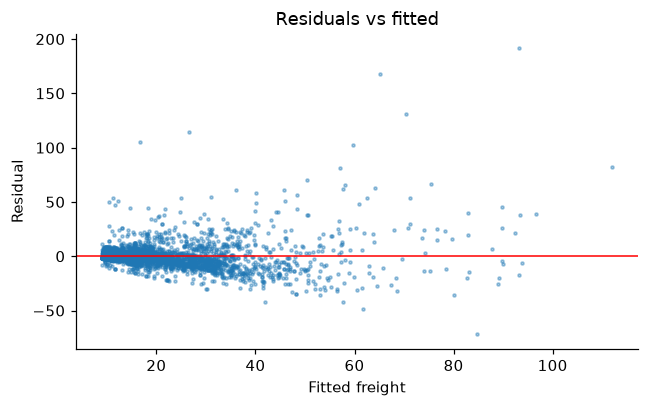

In [8]:
e, n_, k_ = m1["e"], m1["n"], m1["k"]
aux = ols(X, e ** 2); lm = n_ * aux["r2"]; p_bp = stats.chi2.sf(lm, k_ - 1)

X2 = X.copy(); X2[:, iw] = np.log1p(Xdf["weight_kg"].values); X2[:, ip] = np.log(np.maximum(Xdf["price"].values, 0.01))
e2 = ols(X2, np.log1p(yv))["e"]
R.update(lm=f"{lm:,.0f}", se_ratio_w=f"{m1['se_hc3'][iw] / m1['se_ols'][iw]:.1f}",
         sk=f"{stats.skew(e):.2f}", ku=f"{stats.kurtosis(e):.0f}", sk_log=f"{stats.skew(e2):.2f}", ku_log=f"{stats.kurtosis(e2):.0f}")
print(f"Breusch-Pagan: LM = {lm:,.0f}, p {p_fmt(p_bp)}")

fig, ax = plt.subplots(figsize=(6, 3.8))
idx = np.random.RandomState(0).choice(len(e), 4000, replace=False)
ax.scatter(m1["fitted"][idx], e[idx], s=4, alpha=0.4); ax.axhline(0, color="red", linewidth=1)
ax.set(xlabel="Fitted freight", ylabel="Residual", title="Residuals vs fitted")
plt.tight_layout(); plt.show()

**Constant variance fails** (Breusch-Pagan LM = 10,489, p < 0.001), and the residuals fan out as the fitted value rises, which is why robust standard errors are used. The robust standard error for weight is about 3.3 times the classic one. The residuals are also strongly right-skewed (skewness 4.72, excess kurtosis 73). A log transformation reduces this (skewness -2.10, excess kurtosis 18) but does not remove it. Coefficient intervals remain reliable at this sample size; prediction intervals from this model would not.

## Summary

| Question | Method | Finding |
|---|---|---|
| 1. Freight by weight | Welch ANOVA, Kruskal-Wallis, Bonferroni post-hoc tests, Pearson and Spearman | All tiers differ (p < 0.001); weight tier explains about 13% of freight variation (eta-squared 0.130); Heavy minus Light is 12.92 (95% CI 12.68 to 13.17). Pearson r = 0.61, Spearman rho = 0.45. |
| 2. Drivers of freight | OLS with robust standard errors | 2.26 per kg (CI 2.20 to 2.32); R-squared 0.539; variance not constant and errors skewed. |

**Limits.** The data is observational, so results describe association, not cause. Items in the same order are not independent, which makes the p-values optimistic.

**To rerun:** place `cleaned_combined_view.csv` beside this notebook and run all cells. Needs pandas, numpy, scipy and matplotlib.